# Q1F | Final Predictions

# Imports

In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from Q1.consts import TRAIN_PATH, TEST_PATH, COLUMNS, TARGET, MODEL_OUTPUT_DIR

from Q1.utils import CROSS_VALIDATION

# Fetch Data

In [2]:
# the complete training rows: the rows both models were fit on in Parts D and E
train_df = pd.read_csv(TRAIN_PATH).dropna()
test_df = pd.read_csv(TEST_PATH)

FEATURES = [val['col'] for key, val in COLUMNS.items() if key != 'LL']
print(f"complete train rows: {len(train_df)}")
print(f"test rows: {len(test_df)} | test rows with a missing value: {test_df.isna().any(axis=1).sum()}")

complete train rows: 1374
test rows: 334 | test rows with a missing value: 0


# Method
**Models.** Parts D and E each selected one model with cross-validation on the training data, fit it once on the complete training rows and saved it. Both are loaded here exactly as they were saved. Nothing is refit and no hyperparameter changes in this notebook.

**Test data.** The test rows were not used in Part D or Part E. They are used once, here, to score the two saved models.

**No preprocessing.** Each saved model is a full pipeline that takes the 8 raw feature columns. The scaling, the hinge columns of the linear model and the polynomial columns of the polynomial model are all steps inside it, using the values learned from the training rows.

**Metric.** RMSE (root mean squared error), the same metric as in Parts D and E. It is in the same units as Life Ladder. The training RMSE of each model is computed here as well, on the complete training rows, so each test score can be read next to it.

# Load Models

In [3]:
MODELS = {
	"Linear regression": joblib.load(MODEL_OUTPUT_DIR / 'linear_regression.joblib'),
	"Polynomial regression": joblib.load(MODEL_OUTPUT_DIR / 'polynomial_regression.joblib'),
}

# the steps and the chosen hyperparameters, read back from the saved models themselves
for name, model in MODELS.items():
	sgd = model[-1]
	print(f"{name}: {' > '.join(type(step).__name__ for step in model)}")
	print(f"\tpenalty {sgd.penalty} | alpha {sgd.alpha} | eta0 {sgd.eta0} | epochs run {sgd.n_iter_} | coefficients {len(sgd.coef_)}")
	if 'polynomialfeatures' in model.named_steps:
		print(f"\tdegree {model.named_steps['polynomialfeatures'].degree}")

Linear regression: FunctionTransformer > StandardScaler > SGDRegressor
	penalty l2 | alpha 0.01 | eta0 0.01 | epochs run 8 | coefficients 11
Polynomial regression: StandardScaler > PolynomialFeatures > StandardScaler > SGDRegressor
	penalty l1 | alpha 0.001 | eta0 0.01 | epochs run 12 | coefficients 44
	degree 2


# Predictions on the Test Data
Each model predicts Life Ladder for every test row from the 8 raw feature columns. The first rows are shown next to the actual values.

In [4]:
predictions = pd.DataFrame({"actual": test_df[TARGET]})
for name, model in MODELS.items():
	predictions[name] = model.predict(test_df[FEATURES])

print(f"predictions per model: {len(predictions)}")
predictions.head(10).round(3)

predictions per model: 334


,actual,Linear regression,Polynomial regression
0,6.502,6.722,6.693
1,6.201,5.977,6.162
2,4.573,4.882,4.942
3,5.786,5.822,5.999
4,7.025,7.212,7.170
5,5.795,6.255,6.098
6,3.268,4.722,4.002
7,4.349,4.865,4.280
8,4.803,4.739,4.582
9,7.175,7.298,7.143


# Test RMSE

In [5]:
summary = pd.DataFrame({
	name: {
		"train RMSE": CROSS_VALIDATION.rmse_of(train_df[TARGET], model.predict(train_df[FEATURES])),
		"test RMSE": CROSS_VALIDATION.rmse_of(test_df[TARGET], predictions[name]),
	}
	for name, model in MODELS.items()
}).T
summary["test minus train"] = summary["test RMSE"] - summary["train RMSE"]

difference = summary.loc["Polynomial regression", "test RMSE"] - summary.loc["Linear regression", "test RMSE"]
print(f"polynomial test RMSE minus linear test RMSE: {difference:+.4f} (below 0 = polynomial is better)")
summary.round(4)

polynomial test RMSE minus linear test RMSE: -0.0012 (below 0 = polynomial is better)


,train RMSE,test RMSE,test minus train
Linear regression,0.5115,0.5217,0.0102
Polynomial regression,0.4952,0.5205,0.0254


## Predicted Against Actual
One dot per test row. A dot on the diagonal is a perfect prediction. A dot above it was predicted too high, and a dot below it too low.

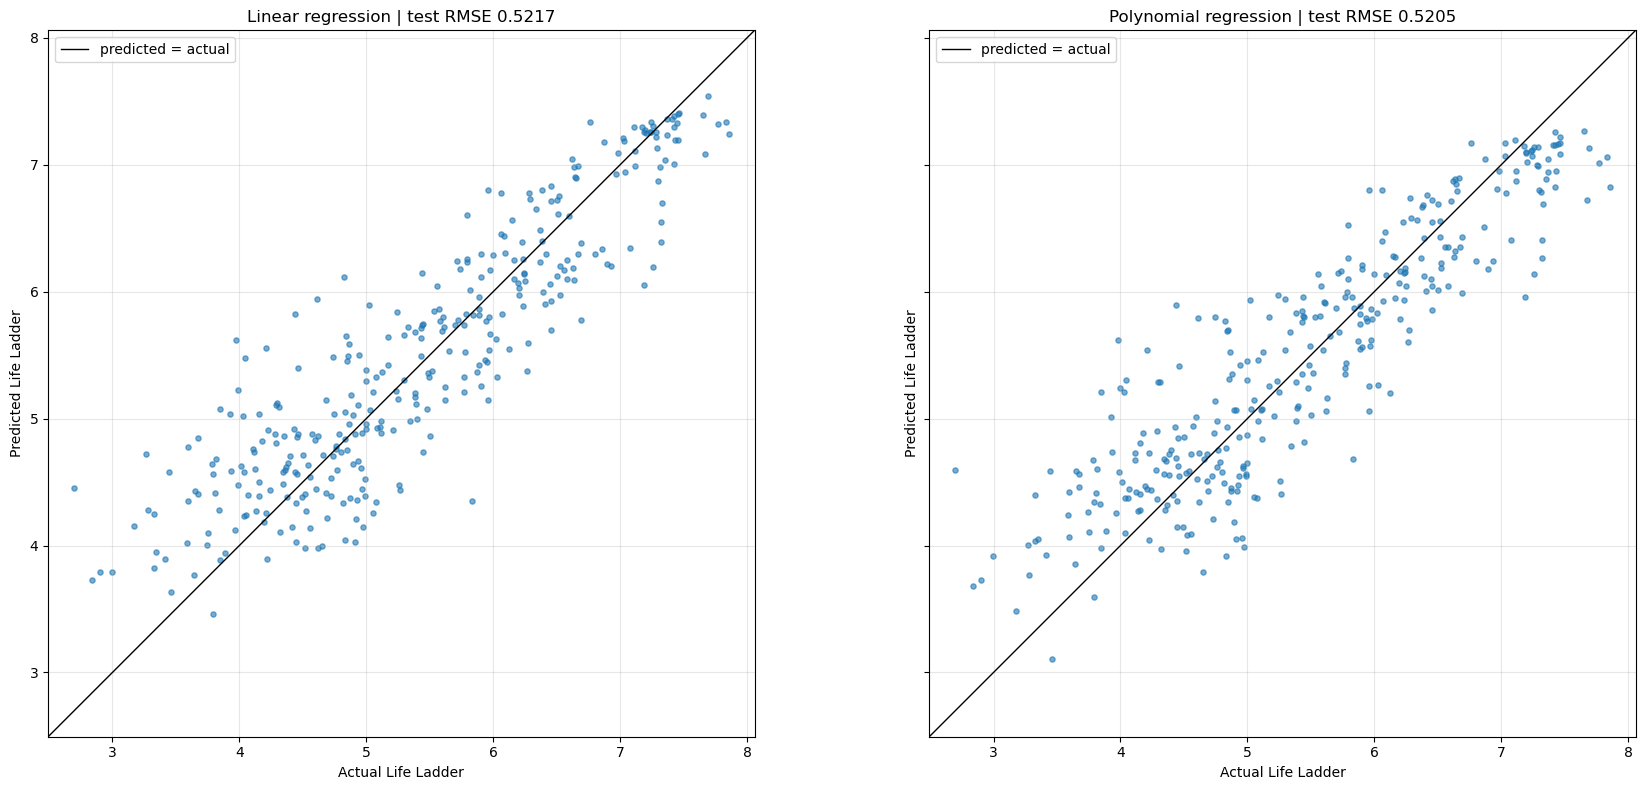

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharex=True, sharey=True)

# one range for both axes of both panels, so the diagonal means the same thing in each
low = predictions.min().min() - 0.2
high = predictions.max().max() + 0.2

for ax, name in zip(axes, MODELS):
	ax.scatter(predictions["actual"], predictions[name], s=14, alpha=0.6, color="C0")
	ax.plot([low, high], [low, high], color="black", linewidth=1, label="predicted = actual")
	ax.set_xlim(low, high)
	ax.set_ylim(low, high)
	ax.set_aspect("equal")
	ax.set_xlabel(f"Actual {TARGET}")
	ax.set_ylabel(f"Predicted {TARGET}")
	ax.set_title(f"{name} | test RMSE {summary.loc[name, 'test RMSE']:.4f}")
	ax.grid(alpha=0.3)
	ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

**Findings.** Both saved models were loaded and used exactly as Parts D and E left them. The linear model is Ridge (`penalty='l2'`, alpha 0.01, eta0 0.01) with 11 coefficients. The polynomial model is degree 2 with Lasso (`penalty='l1'`, alpha 0.001, eta0 0.01) and 44 coefficients. Each predicted all 334 test rows from the 8 raw columns.

- **Test RMSE.** The linear model scores 0.5217 and the polynomial model scores 0.5205. For both, a typical miss is about 0.52 points of Life Ladder.
- **Linear against polynomial.** The polynomial model is ahead by 0.0012, a difference in the third decimal. This notebook has one test set and no measure of noise for that difference, so it does not show that either model is the better one. On the test data the two perform the same.
- **Training against test.** Both models score a little worse on the test rows than on the rows they were fit on, which is expected for rows a model has not seen. The gap is 0.0102 for the linear model (0.5115 to 0.5217) and 0.0254 for the polynomial model (0.4952 to 0.5205). On the training rows the polynomial model leads by 0.0163. On the test rows only 0.0012 of that lead is left. Its extra columns fit the training rows more closely without predicting new rows any better, which is mild overfitting. Neither gap is large.
- **Where the predictions miss.** In both panels the dots follow the diagonal and sit on both sides of it through the middle of the range. Both models pull the extremes toward the middle. Rows with an actual value below about 3.5 are nearly all predicted too high (ex row 6 of the table above: actual 3.268, predicted 4.722 and 4.002), and rows with an actual value above about 7.5 are all predicted too low.

**Summary.** On data neither model has seen, the best linear model and the best polynomial model both miss by about 0.52 (test RMSE 0.5217 and 0.5205). The polynomial model fits the training rows better, but that does not carry over to the test rows.

# Reproducibility
This notebook has no random step. It loads the two models saved by Parts D and E, which were fit with `random_state=42`, and only predicts with them. Running Part D, Part E and then this notebook again gives the same numbers.